In [1]:
#1
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Display all columns when showing a DataFrame
pd.set_option("display.max_columns", None)

# Display numbers neatly
pd.set_option("display.float_format", "{:.2f}".format)

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
# Step 2: Load excel data
# Find the Excel dataset in the current project folder
data_file = Path("Apexplanet_DataAnalytics_Dataset.xlsx")

if not data_file.exists():
    raise FileNotFoundError(
        "Excel file not found. Put Apexplanet_DataAnalytcs_Dataset.xlsx "
        "in the same folder as this notebook."
    )

# Load the original dataset
df = pd.read_excel(data_file)

# Create a working copy so the original data stays unchanged
clean_df = df.copy()

print("Dataset loaded successfully!")
print("Number of rows:", clean_df.shape[0])
print("Number of columns:", clean_df.shape[1])

display(clean_df.head())

Dataset loaded successfully!
Number of rows: 1000
Number of columns: 12


,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales
0,ORD100002,2025-02-25,CUST5529,Customer_227,30.00,Female,Bengaluru,Rice,Grocery,7,2829.77,19808.39
1,ORD100003,2025-10-14,CUST3127,Customer_182,63.00,Male,Bengaluru,Book,Education,5,27906.16,139530.80
2,ORD100004,2025-05-13,CUST8887,Customer_487,62.00,Female,Bengaluru,Book,Education,8,37491.06,299928.48
3,ORD100005,2025-12-02,CUST2515,Customer_470,65.00,Female,Kolkata,Mobile,Electronics,9,28541.36,256872.24
4,ORD100006,2025-11-20,CUST4796,Customer_380,44.00,Male,Bengaluru,Rice,Grocery,10,14036.59,140365.90


In [5]:
# Step 4: Understand the dataset
  # 4.1 --- Dataset structure

# Display the number of rows and columns
print("Dataset shape:", clean_df.shape)

# Display column names
print("\nColumn names:")
print(clean_df.columns.tolist())

# Display data types and non-null counts
print("\nDataset information:")
clean_df.info()

# Generate descriptive statistics
print("\nNumerical summary:")
display(clean_df.describe())

print("\nCategorical summary:")
display(clean_df.describe(include="object"))

Dataset shape: (1000, 12)

Column names:
['Order_ID', 'Order_Date', 'Customer_ID', 'Customer_Name', 'Age', 'Gender', 'City', 'Product', 'Category', 'Quantity', 'Unit_Price', 'Total_Sales']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order_ID       1000 non-null   object 
 1   Order_Date     1000 non-null   object 
 2   Customer_ID    1000 non-null   object 
 3   Customer_Name  1000 non-null   object 
 4   Age            980 non-null    float64
 5   Gender         1000 non-null   object 
 6   City           987 non-null    object 
 7   Product        1000 non-null   object 
 8   Category       1000 non-null   object 
 9   Quantity       1000 non-null   int64  
 10  Unit_Price     1000 non-null   float64
 11  Total_Sales    1000 non-null   float64
dtypes: float64(3), int64(1), object(8)
memory usage: 93.9+ KB

Num

,Age,Quantity,Unit_Price,Total_Sales
count,980.00,1000.00,1000.00,1000.00
mean,41.36,5.43,25486.78,139399.44
std,13.82,2.84,14179.40,114100.05
min,18.00,1.00,145.78,437.34
25%,30.00,3.00,13895.72,47066.63
50%,41.00,5.00,25398.74,108594.02
75%,54.00,8.00,37512.38,203722.88
max,65.00,10.00,49997.53,493677.50



Categorical summary:


,Order_ID,Order_Date,Customer_ID,Customer_Name,Gender,City,Product,Category
count,1000,1000,1000,1000,1000,987,1000,1000
unique,992,342,947,425,2,8,6,5
top,ORD100050,2025-04-16,CUST2515,Customer_359,Male,Patna,Mobile,Electronics
freq,9,10,3,8,511,135,184,354


In [6]:
# 4.2 ---- Data types
print("Data types before cleaning:")
display(clean_df.dtypes.to_frame(name="Data Type"))

Data types before cleaning:


,Data Type
Order_ID,object
Order_Date,object
Customer_ID,object
Customer_Name,object
Age,float64
Gender,object
City,object
Product,object
Category,object
Quantity,int64


In [7]:
# 4.3 Data dictionary
data_dictionary = pd.DataFrame({
    "Column": [
        "Order_ID", "Order_Date", "Customer_ID", "Customer_Name",
        "Age", "Gender", "City", "Product", "Category",
        "Quantity", "Unit_Price", "Total_Sales"
    ],
    "Description": [
        "Unique identifier for each order",
        "Date when the order was placed",
        "Identifier for the customer",
        "Name of the customer",
        "Age of the customer",
        "Gender of the customer",
        "City associated with the customer",
        "Name of the purchased product",
        "Category of the purchased product",
        "Number of units purchased",
        "Price per unit",
        "Total sales amount for the order"
    ],
    "Expected Data Type": [
        "Text", "Datetime", "Text", "Text",
        "Numeric", "Text", "Text", "Text",
        "Text", "Integer", "Float", "Float"
    ]
})

display(data_dictionary)

,Column,Description,Expected Data Type
0,Order_ID,Unique identifier for each order,Text
1,Order_Date,Date when the order was placed,Datetime
2,Customer_ID,Identifier for the customer,Text
3,Customer_Name,Name of the customer,Text
4,Age,Age of the customer,Numeric
5,Gender,Gender of the customer,Text
6,City,City associated with the customer,Text
7,Product,Name of the purchased product,Text
8,Category,Category of the purchased product,Text
9,Quantity,Number of units purchased,Integer


In [9]:
# Step 5: Assess data quality before cleaning
  # 5.1 --- Missing values
missing_before = clean_df.isnull().sum()

missing_report = pd.DataFrame({
    "Missing Values": missing_before,
    "Missing Percentage": (
        missing_before / len(clean_df) * 100
    ).round(2)
})

print("Missing values before cleaning:")
display(missing_report)

Missing values before cleaning:


,Missing Values,Missing Percentage
Order_ID,0,0.00
Order_Date,0,0.00
Customer_ID,0,0.00
Customer_Name,0,0.00
Age,20,2.00
Gender,0,0.00
City,13,1.30
Product,0,0.00
Category,0,0.00
Quantity,0,0.00


In [10]:
# 5.2 --- Duplicate rows
duplicate_count = clean_df.duplicated().sum()

print("Complete duplicate rows:", duplicate_count)

Complete duplicate rows: 0


In [11]:
# 5.3 --- Check categorical consistency
categorical_columns = [
    "Gender", "City", "Product", "Category"
]

for column in categorical_columns:
    print(f"\nUnique values in {column}:")
    print(clean_df[column].dropna().unique())


Unique values in Gender:
['Female' 'Male']

Unique values in City:
['Bengaluru' 'Kolkata' 'Hyderabad' 'Patna' 'Mumbai' 'Delhi' 'Gaya' 'Pune']

Unique values in Product:
['Rice' 'Book' 'Mobile' 'Laptop' 'Shoes' 'Chair']

Unique values in Category:
['Grocery' 'Education' 'Electronics' 'Fashion' 'Furniture']


In [12]:
# 5.4 --- Check invalid numerical values
numeric_columns = [
    "Age", "Quantity", "Unit_Price", "Total_Sales"
]

for column in numeric_columns:
    print(
        f"{column}: "
        f"{(clean_df[column] <= 0).sum()} values are zero or negative"
    )

Age: 0 values are zero or negative
Quantity: 0 values are zero or negative
Unit_Price: 0 values are zero or negative
Total_Sales: 0 values are zero or negative


In [13]:
 # 5.5 --- Check date format
print("Order_Date data type before conversion:")
print(clean_df["Order_Date"].dtype)

display(clean_df[["Order_Date"]].head(10))

Order_Date data type before conversion:
object


,Order_Date
0,2025-02-25
1,2025-10-14
2,2025-05-13
3,2025-12-02
4,2025-11-20
5,2025-12-31
6,2025-10-14
7,2025-12-05
8,2025-11-21
9,2025-04-16


In [14]:
# Step 6: Clean and transform the data

# 1. Standardize column names by removing accidental spaces
clean_df.columns = clean_df.columns.str.strip()

# 2. Remove leading/trailing spaces from text values
text_columns = clean_df.select_dtypes(
    include=["object", "string"]
).columns

for column in text_columns:
    clean_df[column] = clean_df[column].apply(
        lambda value: value.strip() if isinstance(value, str) else value
    )

# 3. Convert Order_Date to datetime
# The dataset previously used YYYY-MM-DD format.
clean_df["Order_Date"] = pd.to_datetime(
    clean_df["Order_Date"],
    format="%Y-%m-%d",
    errors="coerce"
)

# 4. Convert numerical columns to numeric values safely
for column in ["Age", "Quantity", "Unit_Price", "Total_Sales"]:
    clean_df[column] = pd.to_numeric(
        clean_df[column], errors="coerce"
    )

# 5. Fill missing Age values with the median
median_age = clean_df["Age"].median()
clean_df["Age"] = clean_df["Age"].fillna(median_age)

# 6. Fill missing City values with "Unknown"
clean_df["City"] = clean_df["City"].fillna("Unknown")

print("Cleaning and transformation completed.")
display(clean_df.head())


Cleaning and transformation completed.


,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales
0,ORD100002,2025-02-25,CUST5529,Customer_227,30.00,Female,Bengaluru,Rice,Grocery,7,2829.77,19808.39
1,ORD100003,2025-10-14,CUST3127,Customer_182,63.00,Male,Bengaluru,Book,Education,5,27906.16,139530.80
2,ORD100004,2025-05-13,CUST8887,Customer_487,62.00,Female,Bengaluru,Book,Education,8,37491.06,299928.48
3,ORD100005,2025-12-02,CUST2515,Customer_470,65.00,Female,Kolkata,Mobile,Electronics,9,28541.36,256872.24
4,ORD100006,2025-11-20,CUST4796,Customer_380,44.00,Male,Bengaluru,Rice,Grocery,10,14036.59,140365.90


In [15]:
# Step 7: Check data quality after cleaning
  #7.1 ---- Missing values aftr cleaning
missing_after = clean_df.isnull().sum()

print("Missing values after cleaning:")
display(missing_after.to_frame(name="Missing Values"))

Missing values after cleaning:


,Missing Values
Order_ID,0
Order_Date,0
Customer_ID,0
Customer_Name,0
Age,0
Gender,0
City,0
Product,0
Category,0
Quantity,0


In [16]:
# 7.2 ---- Duplicates after cleaning

print("Duplicate rows after cleaning:", clean_df.duplicated().sum())

Duplicate rows after cleaning: 0


In [17]:
# 7.3 --- Validate sales calculations

# Expected sales = Quantity × Unit_Price
expected_sales = clean_df["Quantity"] * clean_df["Unit_Price"]

# Compare actual and expected sales, allowing for tiny floating-point differences
valid_sales = np.isclose(
    clean_df["Total_Sales"],
    expected_sales,
    rtol=1e-5,
    atol=0.01,
    equal_nan=False
)

sales_mismatches = int((~valid_sales).sum())

print("Sales calculation mismatches:", sales_mismatches)

Sales calculation mismatches: 0


In [18]:
# 7.4 --- Detect potential outliers using IQR

outlier_summary = {}

for column in ["Age", "Quantity", "Unit_Price", "Total_Sales"]:
    values = clean_df[column].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_mask = (
        (clean_df[column] < lower_bound) |
        (clean_df[column] > upper_bound)
    )

    outlier_summary[column] = {
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Potential Outliers": int(outlier_mask.sum())
    }

outlier_report = pd.DataFrame(outlier_summary).T
display(outlier_report)

,Q1,Q3,IQR,Lower Bound,Upper Bound,Potential Outliers
Age,30.00,53.00,23.00,-4.50,87.50,0.00
Quantity,3.00,8.00,5.00,-4.50,15.50,0.00
Unit_Price,13895.72,37512.38,23616.66,-21529.27,72937.37,0.00
Total_Sales,47066.63,203722.88,156656.25,-187917.74,438707.26,19.00


In [19]:
# step 8: Save the cleaned dataset
output_csv = Path("sales_data_cleaned.csv")

clean_df.to_csv(output_csv, index=False)

print("Cleaned dataset saved successfully!")
print("File:", output_csv.resolve())
print("Final dataset shape:", clean_df.shape)

Cleaned dataset saved successfully!
File: C:\Users\gauri\apnacollege-demo\Apexplanetinternship\sales_data_cleaned.csv
Final dataset shape: (1000, 12)


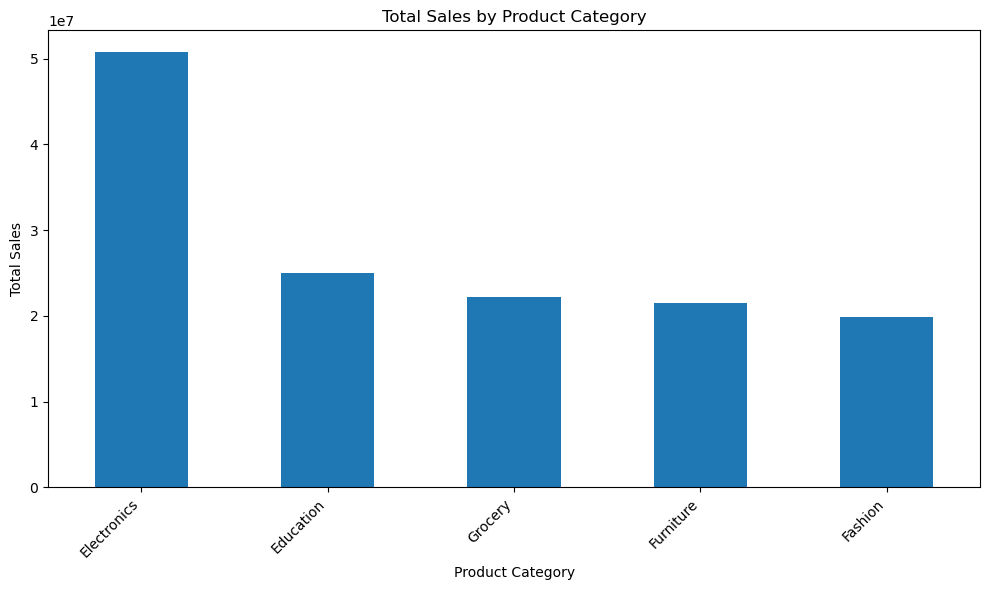

Chart saved as sales_analysis.png


In [20]:
# Step 9: Create a sales analysis chart
# Total sales by product category
sales_by_category = (
    clean_df.groupby("Category", dropna=False)["Total_Sales"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
sales_by_category.plot(kind="bar")
plt.title("Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig("sales_analysis.png", dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved as sales_analysis.png")